Training vgg


vgg Epoch 1/5:   0%|          | 0/7 [00:00<?, ?it/s]

vgg Epoch 1 Train: 9.0 Val: 15.0


vgg Epoch 2/5:   0%|          | 0/7 [00:00<?, ?it/s]

vgg Epoch 2 Train: 12.5 Val: 15.0


...

googlenet Epoch 3 Train: 80.25 Val: 57.0


googlenet Epoch 4/5:   0%|          | 0/7 [00:00<?, ?it/s]

googlenet Epoch 4 Train: 88.5 Val: 67.0


googlenet Epoch 5/5:   0%|          | 0/7 [00:00<?, ?it/s]

googlenet Epoch 5 Train: 93.5 Val: 67.0


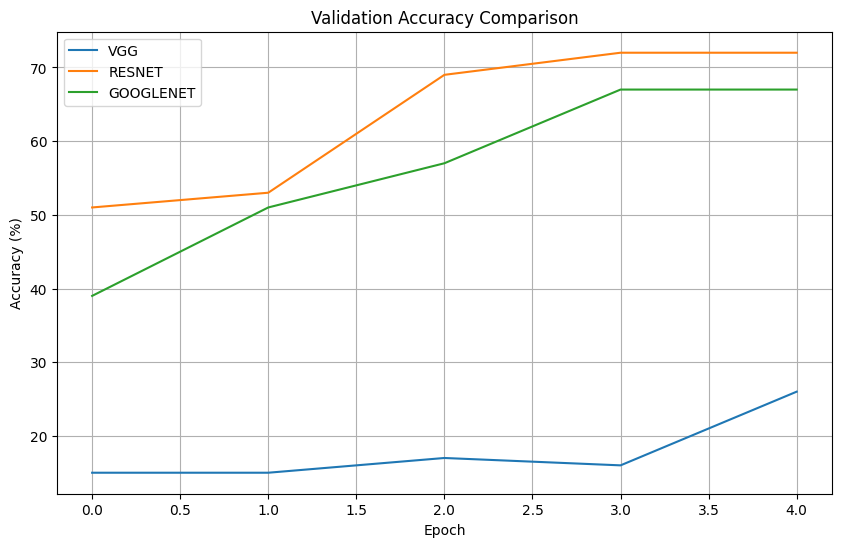

Image not found


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, random_split, Subset
import matplotlib.pyplot as plt
from PIL import Image
import os
from tqdm.notebook import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform
)

dataset = Subset(dataset, range(500))

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size]
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

def train_and_evaluate(model, name, num_epochs=5):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    train_accs = []
    val_accs = []

    for epoch in range(num_epochs):
        model.train()
        correct = 0
        total = 0

        # Add a progress bar for the training loader
        progress_bar = tqdm(train_loader, desc=f"{name} Epoch {epoch + 1}/{num_epochs}", leave=False)
        for inputs, labels in progress_bar:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

            # Update progress bar description with loss
            progress_bar.set_postfix(loss=loss.item())

        train_accs.append(100 * correct / total)

        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                _, predicted = outputs.max(1)

                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_accs.append(100 * correct / total)

        print(
            name, "Epoch", epoch + 1,
            "Train:", round(train_accs[-1], 2),
            "Val:", round(val_accs[-1], 2)
        )

    return model, train_accs, val_accs

def get_model(name):
    if name == "vgg":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(4096, 10)

    elif name == "resnet":
        # Updated to use modern weights argument to resolve deprecation warnings
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 10)

    else:
        # Updated to use modern weights argument to resolve deprecation warnings
        model = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 10)

    return model

results = {}
trained_models = {}

names = ["vgg", "resnet", "googlenet"]

for i in range(3):
    name = names[i]
    print("Training", name)

    model = get_model(name)

    trained_model, train_acc, val_acc = train_and_evaluate(
        model, name, 5
    )

    results[name] = (train_acc, val_acc)
    trained_models[name] = trained_model

plt.figure(figsize=(10, 6))

for name in names:
    train_acc, val_acc = results[name]
    plt.plot(val_acc, label=name.upper())

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

def predict_image(image_path, models_dict):
    image = Image.open(image_path).convert('RGB')
    image = transform(image).unsqueeze(0).to(device)

    for name in names:
        model = models_dict[name]
        model.eval()

        with torch.no_grad():
            outputs = model(image)
            _, predicted = outputs.max(1)

        print(name.upper(), "=>", class_names[predicted.item()])

custom_image_path = "download.jpeg"

if os.path.exists(custom_image_path):
    predict_image(custom_image_path, trained_models)
else:
    print("Image not found")